In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem.PandasTools import LoadSDF
import tmap as tm
from map4 import MAP4Calculator
import warnings, json, traceback
import pickle
from progress_bar import print_progress_bar
warnings.filterwarnings('ignore')

In [2]:
def pickle_dump(file_name, data):
    with open(file_name, 'wb') as f:
        pickle.dump(data, f)
def pickle_load(file_name):
    with open(file_name, 'rb') as f:
        return pickle.load(f)

In [3]:
DATA_FOLDER = 'database_unification_data/'

### Data file paths

In [4]:
 # SDFs
lotus_sdf_path = f'{DATA_FOLDER}LOTUS_2021_03_simple.sdf'
pubchem_kegg_path = f'{DATA_FOLDER}PubChem_substance_text_KEGG_records.sdf'
lipidmaps_sdf_path = f'{DATA_FOLDER}lipid_structures.sdf'
rhea_sdf_path = f'{DATA_FOLDER}rhea.sdf'

# TSVs
metanetx_tsv_path = f'{DATA_FOLDER}chem_prop.tsv'

# JSONs
peptides_json_path = f'{DATA_FOLDER}peptides_smiles.json'

### Lipidmaps

In [5]:
df_lipids = LoadSDF(lipidmaps_sdf_path, smilesName='SMILES', molColName='Molecule', strictParsing=True)

RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.
[12:34:49] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 52 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 52 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 77 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 77 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 81 ignored. by rule 1a.
RDKit WARNING: [12:34:49] Warning: conflicting stereochemistry at atom 81 ignored. by rule 1a.
[12:34:49] Warning: conflicting stereochemistry at atom 52 ignored. by rule 1a.
[12:34:49] Warning: conflicting stereochemistry at atom 49 ignored. by rule 1a.


In [6]:
df_lipids = df_lipids[['LM_ID', 'SMILES', 'Molecule']]

In [7]:
len(df_lipids)

47382

,LM_ID,SMILES,Molecule
0,LMFA00000001,C=CCCCCC(C)CCCCCC#CCCC(OC)C(=O)OC(=O)C(CCC#CCC...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,LMFA00000002,CCCCCCC[C@H](O)CC(=O)N[C@@H](CO)C(=O)O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,LMFA00000003,CCCCCCCCCCCCCCCC(=O)OC(CCCCCCCCCCCCCC)CC(=O)N[...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,LMFA00000004,CC/C=C\C/C=C\C/C=C\CCCCCCCC(=O)N[C@@H](CCC(N)=...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,LMFA00000005,CC(C)CCCCCCCCCCCCCC(=O)OC(CCCCCCCCCCCC(C)C)CC(...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

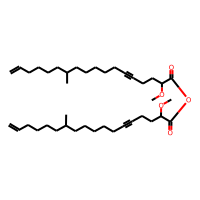
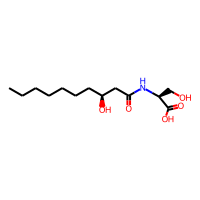
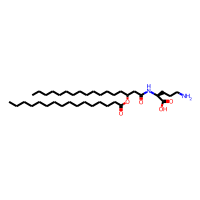
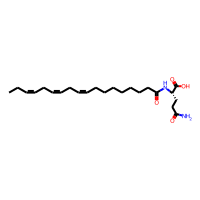
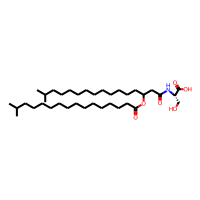

In [14]:
df_lipids.head()

In [45]:
pickle_dump('database_unification_data/pickles/lipidmaps.pkl', df_lipids)

### LOTUS

In [6]:
df_lotus = LoadSDF(lotus_sdf_path, smilesName='SMILES', molColName='Molecule')

In [7]:
df_lotus = df_lotus[['lotus_id', 'SMILES', 'Molecule']]

,lotus_id,SMILES,Molecule
0,LTS0000001,CC(C)CCCCCC=CC=CC(O)=NC(C(O)=NC1CC(O)CCN=C(O)C...,
1,LTS0000002,CC(C)=CC(O)=NCCc1ccc2c(c1)C=CC(C)(C)O2,
2,LTS0000003,CC1(C)CCC2(C(=O)OC3OC(CO)C(O)C(O)C3O)CCC3(C)C(...,
3,LTS0000004,CC(=O)OCC(CC(C)C)N=C(O)C(N=C(O)C1CCCN1C(=O)C(C...,
4,LTS0000005,CC1=C(O)c2c(oc(-c3ccccc3)cc2=O)C(C)(C)C1=O,

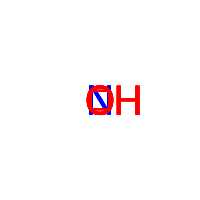
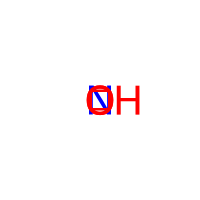
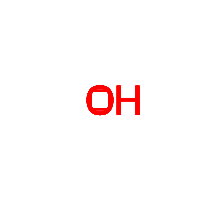
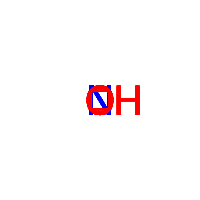
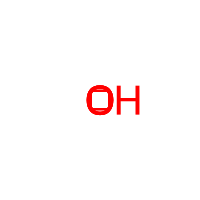

In [8]:
df_lotus.head()

In [46]:
pickle_dump('database_unification_data/pickles/lotus.pkl', df_lotus)

### MetaNetX

In [9]:
df_metanetx = pd.read_csv(metanetx_tsv_path, sep='\t', header=None, skiprows=353, names=['ID', 'name', 'reference', 'formula', 'charge', 'mass', 'InChI', 'InChIKey', 'SMILES'])

In [10]:
df_metanetx

,ID,name,reference,formula,charge,mass,InChI,InChIKey,SMILES
0,MNXM01,PMF,mnx:PMF,H,1.0,1.00794,InChI=1S/p+1,InChIKey=GPRLSGONYQIRFK-UHFFFAOYSA-N,[H+]
1,MNXM02,OH(-),mnx:HYDROXYDE,OH,-1.0,17.00734,InChI=1S/H2O/h1H2/p-1,InChIKey=XLYOFNOQVPJJNP-UHFFFAOYSA-M,[O-][H]
2,MNXM03,H3O(+),mnx:OXONIUM,H3O,1.0,19.02322,InChI=1S/H2O/h1H2/p+1,InChIKey=XLYOFNOQVPJJNP-UHFFFAOYSA-O,[OH3+]
3,MNXM1,H(+),mnx:PROTON,H,1.0,1.00794,InChI=1S/p+1,InChIKey=GPRLSGONYQIRFK-UHFFFAOYSA-N,[H+]
4,MNXM10,NADH,chebi:57945,C21H27N7O14P2,-2.0,663.11022,InChI=1S/C21H29N7O14P2/c22-17-12-19(25-7-24-17...,InChIKey=BOPGDPNILDQYTO-NNYOXOHSSA-L,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)([O-])OP(=O)(...
...,...,...,...,...,...,...,...,...,...
1292148,MNXM999996,"1-(14Z,17Z,20Z,23Z,26Z-dotriacontapentaenoyl)-...",slm:000692384,C73H121NO9P,-1.0,1186.87844,InChI=1S/C73H122NO9P/c1-4-7-10-13-16-19-22-24-...,InChIKey=VNZHXXLXDVSBLA-IZNAGHOASA-M,CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCC(=O)NC...
1292149,MNXM999997,"1-(14Z,17Z,20Z,23Z,26Z-dotriacontapentaenoyl)-...",slm:000692385,C69H121NO9P,-1.0,1138.87844,InChI=1S/C69H122NO9P/c1-4-7-10-13-16-19-22-24-...,InChIKey=FTBDAPNXHPOOLH-RUXWUTLCSA-M,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCCCCC...
1292150,MNXM999998,"1-(14Z,17Z,20Z,23Z,26Z-dotriacontapentaenoyl)-...",slm:000692386,C69H119NO9P,-1.0,1136.86279,InChI=1S/C69H120NO9P/c1-4-7-10-13-16-19-22-24-...,InChIKey=UTTKGJJHRRHZRR-BNJOEXAFSA-M,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCCCCC...
1292151,MNXM999999,"1-(14Z,17Z,20Z,23Z,26Z-dotriacontapentaenoyl)-...",slm:000692387,C71H121NO9P,-1.0,1162.87844,InChI=1S/C71H122NO9P/c1-4-7-10-13-16-19-22-24-...,InChIKey=BSOMIPWIPDKFRW-FMCFKDERSA-M,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCCCCC...


In [11]:
try:
    for i in range(len(df_metanetx)):
        Chem.MolFromSmiles(df_metanetx.iloc[i]['SMILES'])
except:
    print(i)

RDKit WARNING: [14:58:40] WARNING: not removing hydrogen atom without neighbors
[14:58:40] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:40] WARNING: not removing hydrogen atom without neighbors
[14:58:40] WARNING: not removing hydrogen atom without neighbors


778


In [12]:
df_metanetx.iloc[778]['SMILES']

nan

In [13]:
df_metanetx = df_metanetx[df_metanetx['SMILES'].notna()]

In [14]:
df_metanetx = df_metanetx.reset_index(drop=True)

In [15]:
df_metanetx.head()

,ID,name,reference,formula,charge,mass,InChI,InChIKey,SMILES
0,MNXM01,PMF,mnx:PMF,H,1.0,1.00794,InChI=1S/p+1,InChIKey=GPRLSGONYQIRFK-UHFFFAOYSA-N,[H+]
1,MNXM02,OH(-),mnx:HYDROXYDE,OH,-1.0,17.00734,InChI=1S/H2O/h1H2/p-1,InChIKey=XLYOFNOQVPJJNP-UHFFFAOYSA-M,[O-][H]
2,MNXM03,H3O(+),mnx:OXONIUM,H3O,1.0,19.02322,InChI=1S/H2O/h1H2/p+1,InChIKey=XLYOFNOQVPJJNP-UHFFFAOYSA-O,[OH3+]
3,MNXM1,H(+),mnx:PROTON,H,1.0,1.00794,InChI=1S/p+1,InChIKey=GPRLSGONYQIRFK-UHFFFAOYSA-N,[H+]
4,MNXM10,NADH,chebi:57945,C21H27N7O14P2,-2.0,663.11022,InChI=1S/C21H29N7O14P2/c22-17-12-19(25-7-24-17...,InChIKey=BOPGDPNILDQYTO-NNYOXOHSSA-L,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)([O-])OP(=O)(...


In [16]:
df_metanetx['Molecule'] = df_metanetx.apply(lambda x: Chem.MolFromSmiles(x['SMILES']), axis=1)

RDKit WARNING: [14:58:42] WARNING: not removing hydrogen atom without neighbors
[14:58:42] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:42] WARNING: not removing hydrogen atom without neighbors
[14:58:42] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:54] WARNING: not removing hydrogen atom without neighbors
[14:58:54] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:54] WARNING: not removing hydrogen atom without neighbors
[14:58:54] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:55] WARNING: not removing hydrogen atom without neighbors
[14:58:55] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:55] WARNING: not removing hydrogen atom without neighbors
[14:58:55] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:58:56] WARNING: not removing hydrogen atom without neighbors
[14:58:56] WARNING: not removing hydrogen atom wit

In [17]:
df_metanetx = df_metanetx[['ID', 'SMILES', 'Molecule']]

In [18]:
len(df_metanetx)

1248094

,ID,SMILES,Molecule
0,MNXM01,[H+],"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,MNXM02,[O-][H],"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,MNXM03,[OH3+],"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,MNXM1,[H+],"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,MNXM10,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)([O-])OP(=O)(...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

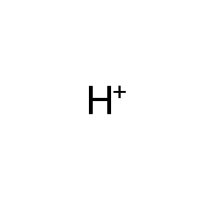
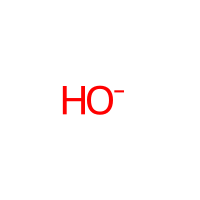
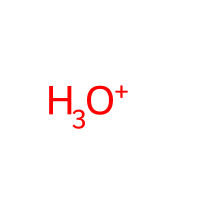
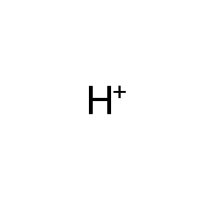
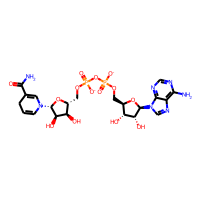

In [19]:
df_metanetx.head()

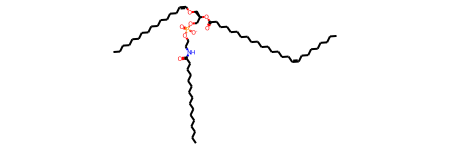

In [20]:
Chem.MolFromSmiles(df_metanetx.iloc[10000]['SMILES'])

In [47]:
pickle_dump('database_unification_data/pickles/metanetx.pkl', df_metanetx)

### Peptides

In [8]:
with open(peptides_json_path, 'r') as json_file:
    peptides = json.load(json_file)
peptides_smiles = [{'ID': p['general']['id'], 'SMILES': p['structure']['smiles']} for p in peptides['peptides']]

In [9]:
len(peptides_smiles)

713

In [11]:
df_peptides = pd.DataFrame.from_dict(peptides_smiles)

In [12]:
df_peptides['Molecule'] = df_peptides.apply(lambda x: Chem.MolFromSmiles(x['SMILES']), axis=1)

,ID,SMILES,Molecule
0,NOR00001,CCCCCCCCCC(=O)NC(Cc1c[nH]c2ccccc12)C(=O)NC(CC(...,
1,NOR00006,CC(C)C(NC(=O)C(CS)NC(=O)CCCC(N)C(=O)O)C(=O)O,
2,NOR00007,CC(C)CC(NC(=O)CNC(=O)C(C)(C)NC(=O)C(NC(=O)C(C)...,
3,NOR00010,C[C@H](C(=O)N[C@H](CCC(=O)N)C(=O)NC(C)(C)C(=O)...,
4,NOR00018,CC[C@H](C)[C@@H]1C(=O)N[C@@H](C(=O)N[C@H](C(=O...,
...,...,...,...
708,NOR01991,CCCCCCCC(CC(=O)NC(CC(C)C)C(=O)NC(CCC(=O)N)C(=O...,
709,NOR01992,C[C@@H]1[C@@H](C(=O)N[C@@H](C(=O)N[C@@H](C(=O)...,
710,NOR01993,CCCCCCC[C@@H](O)CC(N[C@H](C(N[C@H](C(N[C@@H](C...,
711,NOR02012,O=C([C@H](COC([C@@]([C@H](O)CCl)([H])NC([C@@H]...,

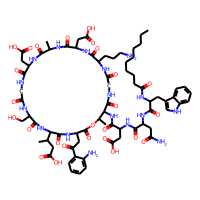
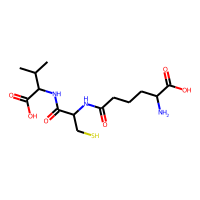
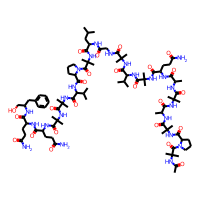
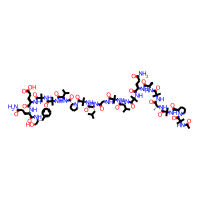
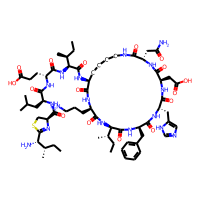
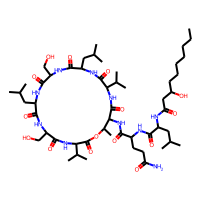
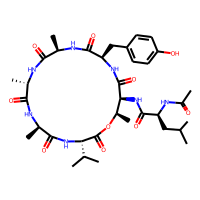
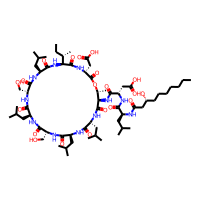
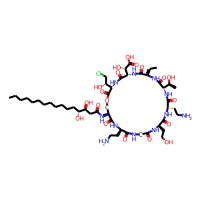
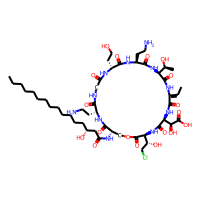

In [13]:
df_peptides

In [48]:
pickle_dump('database_unification_data/pickles/peptides.pkl', df_peptides)

### Rhea

In [26]:
# df_rhea = pd.read_csv(rhea_tsv_path, sep='\t', header=None, names=['RHEA_ID', 'SMILES'])
df_rhea = LoadSDF(rhea_sdf_path, smilesName='SMILES', molColName='Molecule')

RDKit ERROR: [15:06:24] 
RDKit ERROR: 
RDKit ERROR: ****
RDKit ERROR: Post-condition Violation
RDKit ERROR: Element 'e' not found
RDKit ERROR: Violation occurred on line 91 in file /home/conda/feedstock_root/build_artifacts/rdkit_1646569069773/work/Code/GraphMol/PeriodicTable.h
RDKit ERROR: Failed Expression: anum > -1
RDKit ERROR: ****
RDKit ERROR: 
RDKit ERROR: [15:06:25] ERROR: Element 'e' not found
[15:06:24] 

****
Post-condition Violation
Element 'e' not found
Violation occurred on line 91 in file /home/conda/feedstock_root/build_artifacts/rdkit_1646569069773/work/Code/GraphMol/PeriodicTable.h
Failed Expression: anum > -1
****

[15:06:25] ERROR: Element 'e' not found
RDKit WARNING: [15:06:25] WARNING: not removing hydrogen atom with dummy atom neighbors
[15:06:25] WARNING: not removing hydrogen atom with dummy atom neighbors
RDKit WARNING: [15:06:26] WARNING: not removing hydrogen atom with dummy atom neighbors
[15:06:26] WARNING: not removing hydrogen atom with dummy atom neighb

In [27]:
df_rhea = df_rhea[['ID', 'SMILES', 'Molecule']]

,ID,SMILES,Molecule
0,CHEBI:100,COc1ccc2c(c1)O[C@H]1c3ccc(O)cc3OC[C@@H]21,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,CHEBI:10023,C[C@@H](c1ncncc1F)[C@](O)(Cn1cncn1)c1ccc(F)cc1F,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,CHEBI:10036,*OC(*)=O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,CHEBI:10115,CC(C)=CCC[C@H](C)[C@@H]1C=CC(C)=CC1,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,CHEBI:10213,C[C@H]1[C@H](C)CC[C@]2(C)CC[C@]3(C)C(=CC[C@@H]...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

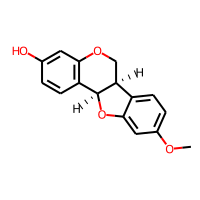
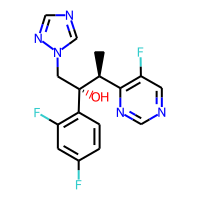
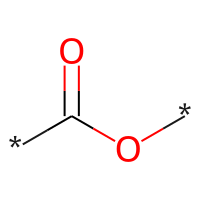
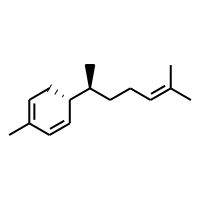
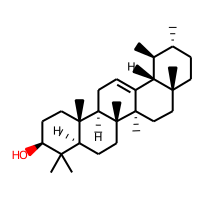

In [28]:
df_rhea.head()

In [29]:
len(df_rhea)

12354

In [49]:
pickle_dump('database_unification_data/pickles/rhea.pkl', df_rhea)

### PubChem Kegg

In [16]:
df_pubchem_kegg = LoadSDF(pubchem_kegg_path, smilesName='SMILES', molColName='Molecule')
df_pubchem_kegg = df_pubchem_kegg[['PUBCHEM_EXT_DATASOURCE_REGID', 'SMILES', 'Molecule']]
# df_pubchem_kegg.rename({'PUBCHEM_COMPOUND_CID': 'CID'}, axis=1, inplace=True)
df_pubchem_kegg.rename({'PUBCHEM_EXT_DATASOURCE_REGID':'KEGG_ID'}, axis=1, inplace=True)

RDKit WARNING: [14:12:18] WARNING: not removing hydrogen atom without neighbors
[14:12:18] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [14:12:19] WARNING: not removing hydrogen atom with dummy atom neighbors
[14:12:19] WARNING: not removing hydrogen atom with dummy atom neighbors
RDKit WARNING: [14:12:19] WARNING: not removing hydrogen atom with dummy atom neighbors
[14:12:19] WARNING: not removing hydrogen atom with dummy atom neighbors
RDKit ERROR: [14:12:20] Explicit valence for atom # 4 N, 4, is greater than permitted
[14:12:20] Explicit valence for atom # 4 N, 4, is greater than permitted
RDKit ERROR: [14:12:20] ERROR: Could not sanitize molecule ending on line 183977
[14:12:20] ERROR: Could not sanitize molecule ending on line 183977
RDKit ERROR: [14:12:20] ERROR: Explicit valence for atom # 4 N, 4, is greater than permitted
[14:12:20] ERROR: Explicit valence for atom # 4 N, 4, is greater than permitted
[14:12:26] Explicit valence for atom # 0 F, 2, is gr

,KEGG_ID,SMILES,Molecule
0,C00001,O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,C00002,Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,C00003,NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,C00004,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,C00005,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
...,...,...,...
41098,G13142,,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
41099,G13144,,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
41100,G13145,,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
41101,G13146,,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

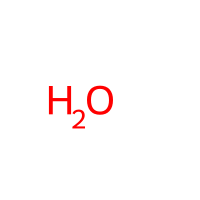
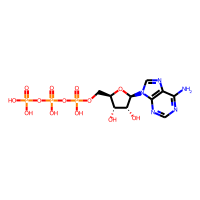
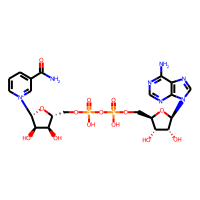
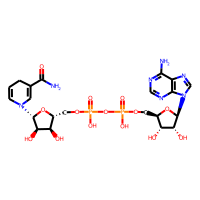
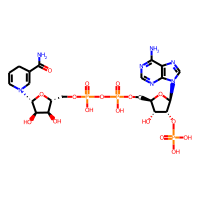
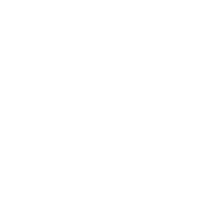
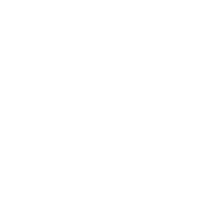
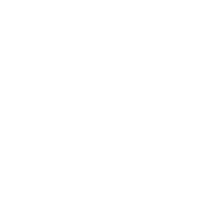
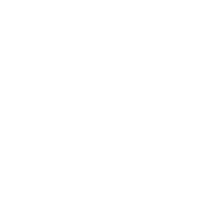
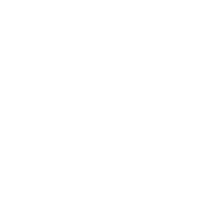

In [17]:
df_pubchem_kegg

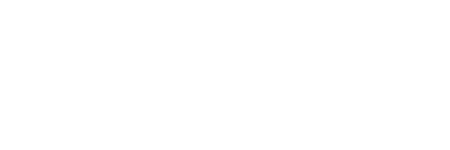

In [21]:
df_pubchem_kegg.iloc[-3]['Molecule']

,KEGG_ID,SMILES,Molecule
0,C00001,O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,C00002,Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,C00003,NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,C00004,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,C00005,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

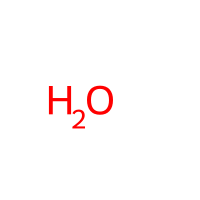
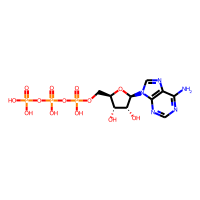
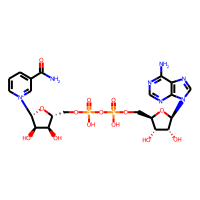
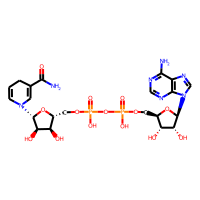
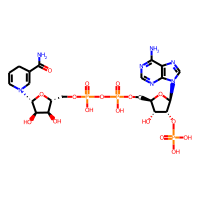

In [31]:
df_pubchem_kegg.head()

In [50]:
pickle_dump('database_unification_data/pickles/pubchem_kegg.pkl', df_pubchem_kegg)

In [32]:
# sdf_filename = 'data/PubChem_substance_text_KEGG_records.sdf'
# df = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule')
# df = df[['PUBCHEM_EXT_DATASOURCE_REGID', 'SMILES', 'Molecule']]
# df.rename({'PUBCHEM_EXT_DATASOURCE_REGID':'KeggID'}, axis=1, inplace=True)
# df = df.drop(df[df['KeggID'].map(lambda x: not str(x).startswith('C'))].index) # Take only compounds with C
# df.head()

In [33]:
dim = 1024
MAP4 = MAP4Calculator(dimensions=dim)
ENC = tm.Minhash(dim)

In [34]:
# This cell computes the fingerprints MAP4 of the LOTUS database.
# Some warnings may appear. It may take some minutes

# fps_lotus = MAP4.calculate_many(df_lotus['Molecule'].values)

In [35]:
def kegg_similarity(smiles, kegg, codes, n=10):
    
    dim = 1024
    MAP4 = MAP4Calculator(dimensions=dim)
    ENC = tm.Minhash(dim)
    
    distances = {}
    fp_query = MAP4.calculate(Chem.MolFromSmiles(smiles))
    for i, fp in enumerate(kegg):
        distances[codes[i]] = ENC.get_distance(fp_query, fp)
        
    # Sort the results
    distances = {k: v for k, v in sorted(distances.items(), key=lambda item: item[1])}
    to_keep = list(distances.keys())[:n+1]
    result = {k: v for k, v in distances.items() if k in to_keep}
    return result

In [36]:
def fp_similarity(fps_total, fps_reference, df_to_test, id_to_test_column_name, df_ids, id_column_name):
    '''
    Function that compares compound fingerprints and gets the distance between each of them.
    If the distance is 1, the compound database id is added to the ids dataframe. If there are no compounds with distance 1,
    the compound is appended to the ids dataframe.
    '''
    dim = 1024
    MAP4 = MAP4Calculator(dimensions=dim)
    ENC = tm.Minhash(dim)

    fps_to_test = fps_total.copy()

    for i, current_fp in enumerate(fps_to_test):
        found = False
        for j, compared_fp in enumerate(fps_reference):
            current_distance = ENC.get_distance(current_fp, compared_fp)
            if current_distance == 0:
                df_ids.iloc[j][id_column_name] = df_to_test.iloc[i][id_to_test_column_name]
                found = True
                break
        if not found:
            new_df_row = {'ID': len(df_ids), id_column_name: df_to_test.iloc[i][id_to_test_column_name]}
            df_ids = df_ids.append(new_df_row, ignore_index=True)
            fps_total.append(current_fp)

In [89]:
def fp_similarity_indiv(df_to_test, id_to_test_column_name, df_ids, id_column_name):
    '''
    Function that compares compound fingerprints and gets the distance between each of them.
    If the distance is 1, the compound database id is added to the ids dataframe. If there are no compounds with distance 1,
    the compound is appended to the ids dataframe.
    '''
    dim = 1024
    MAP4 = MAP4Calculator(dimensions=dim)
    ENC = tm.Minhash(dim)

    df_test = df_to_test.copy()
    df_total = df_ids.copy()

    print_progress_bar(0, len(df_test), suffix=f'(0/{len(df_test)})')
    for i in range(len(df_test)):
        try:
            current_fp = MAP4.calculate(df_test.iloc[i]['Molecule'])
        except Exception as e1:
            current_fp = None
            print(f'Error calculating fp for compound {i} in dataframe to test:\n{str(e1)}')
        found = False
        if current_fp:
            for j in range(len(df_total)):
                try:
                    compared_fp = MAP4.calculate(df_total.iloc[j]['Molecule'])
                except Exception as e2:
                    compared_fp = None
                    print(f'Error calculating fp for compound {j} in ids dataframe:\n{str(e2)}')
                if compared_fp:
                    current_distance = ENC.get_distance(current_fp, compared_fp)
                    if current_distance == 0:
                        df_ids.iloc[j][id_column_name] = df_to_test.iloc[i][id_to_test_column_name]
                        found = True
                        break
            if not found:
                new_df_row = {'ID': len(df_ids), id_column_name: df_test.iloc[i][id_to_test_column_name], 'Molecule': df_test.iloc[i]['Molecule'], 'SMILES': df_test.iloc[i]['SMILES']}
                df_ids = df_ids.append(new_df_row, ignore_index=True)
        print_progress_bar(i + 1, len(df_test), suffix=f'({i}/{len(df_test)})')
    
    return df_ids

In [38]:
compounds_ids = []

In [39]:
len(df_lotus.head())

5

In [88]:
# fps_lipidmaps = MAP4.calculate_many(df_lipids['Molecule'].values)

In [ ]:
# fps_lotus = MAP4.calculate_many(df_lotus['Molecule'].values)

In [ ]:
# fps_metanetx = MAP4.calculate_many(df_metanetx['Molecule'].values)

In [ ]:
# fps_peptides = MAP4.calculate_many(df_peptides['Molecule'].values)

In [ ]:
# fps_rhea = MAP4.calculate_many(df_rhea['Molecule'].values)

In [ ]:
# fps_pubchem_kegg = MAP4.calculate_many(df_pubchem_kegg['Molecule'].values)

RDKit WARNING: [12:03:20] Conflicting single bond directions around double bond at index 0.
[12:03:20] Conflicting single bond directions around double bond at index 0.
RDKit WARNING: [12:03:20]   BondStereo set to STEREONONE and single bond directions set to NONE.
[12:03:20]   BondStereo set to STEREONONE and single bond directions set to NONE.
RDKit WARNING: [12:04:13] Conflicting single bond directions around double bond at index 0.
[12:04:13] Conflicting single bond directions around double bond at index 0.
RDKit WARNING: [12:04:13]   BondStereo set to STEREONONE and single bond directions set to NONE.
[12:04:13]   BondStereo set to STEREONONE and single bond directions set to NONE.
RDKit WARNING: [12:04:42] Conflicting single bond directions around double bond at index 0.
[12:04:42] Conflicting single bond directions around double bond at index 0.
RDKit WARNING: [12:04:42]   BondStereo set to STEREONONE and single bond directions set to NONE.
[12:04:42]   BondStereo set to STEREON

In [20]:
# ENC.get_distance(fps_pubchem_kegg[0], fps_pubchem_kegg[0])

0.0

In [55]:
# Populate compounds ids list with first database (LOTUS)
df_ids = df_lotus.copy()
df_ids.rename({'lotus_id': 'LOTUS_ID'}, axis=1, inplace=True)
df_ids['ID'] = df_ids.index
df_ids['METANETX_ID'] = None
df_ids['PEPTIDE_ID'] = None
df_ids['RHEA_ID'] = None
df_ids['KEGG_ID'] = None
df_ids['LIPIDMAPS_ID'] = None
df_ids['PUBCHEM_ID'] = None

In [44]:
pickle_dump('backups/ids_1.pkl', df_ids)

In [ ]:
# fps_total = fps_lotus.copy()

In [59]:
# type(df_metanetx['Molecule']) == Chem.rdchem.Mol

True

In [ ]:
# df_ids[[isinstance(x, Chem.rdchem.Mol) for x in df_ids['Molecule']]]

In [ ]:
# MAP4.calculate(df_ids.iloc[1]['Molecule'])

In [90]:
# df_testy = fp_similarity_indiv(df_metanetx.head(), 'ID', df_ids.head(), 'METANETX_ID')

In [ ]:
# df_testy

In [ ]:
# vs PUBCHEM
# fp_similarity(fps_total, fps_pubchem_kegg, df_pubchem_kegg, 'CID', df_ids, 'PUBCHEM_ID')
# df_ids = fp_similarity_indiv(df_pubchem_kegg, 'KEGG_ID', df_ids, 'KEGG_ID')

In [ ]:
# vs METANETX
# fp_similarity(fps_total, fps_metanetx, df_metanetx, 'ID', df_ids, 'METANETX_ID')
df_ids = fp_similarity_indiv(df_metanetx, 'ID', df_ids, 'METANETX_ID')

In [ ]:
# vs Peptides
# fp_similarity(fps_total, fps_peptides, df_peptides, 'ID', df_ids, 'PEPTIDE_ID')
df_ids = fp_similarity_indiv(df_peptides, 'ID', df_ids, 'PEPTIDE_ID')

In [ ]:
# vs Rhea
# fp_similarity(fps_total, fps_rhea, df_rhea, 'ID', df_ids, 'RHEA_ID')
df_ids = fp_similarity_indiv(df_rhea, 'ID', df_ids, 'RHEA_ID')

In [ ]:
# vs Kegg
# fp_similarity(fps_total, fps_pubchem_kegg, df_pubchem_kegg, 'KEGG_ID', df_ids, 'KEGG_ID')
df_ids = fp_similarity_indiv(df_pubchem_kegg, 'KEGG_ID', df_ids, 'KEGG_ID')

In [ ]:
# vs Lipidmaps
# fp_similarity(fps_total, fps_lipidmaps, df_lipids, 'LM_ID', df_ids, 'LIPIDMAPS_ID')
df_ids = fp_similarity_indiv(df_lipids, 'LM_ID', df_ids, 'LIPIDMAPS_ID')